<a href="https://colab.research.google.com/github/AscanOfficiel2/MDT-TM_CRC_Microbiome-Framework/blob/main/Sensitivity_analysis_MDT.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

Dose-response rows: 63
Entropy rows: 63

COMPLETE SENSITIVITY RESULTS
Recipient   Donor        Transition  Dominance_threshold  MDT_alpha  Alpha_at_entropy_peak  Peak_entropy  Entropy_MDT_gap  Entropy_precedes_MDT
  Healthy Adenoma Healthy → Adenoma                  0.6       0.60                   0.55        1.3119             0.05                  True
  Healthy Adenoma Healthy → Adenoma                  0.7       0.65                   0.55        1.3119             0.10                  True
  Healthy Adenoma Healthy → Adenoma                  0.8       0.65                   0.55        1.3119             0.10                  True
  Healthy Adenoma Healthy → Adenoma                  0.9       0.65                   0.55        1.3119             0.10                  True
  Healthy  Cancer  Healthy → Cancer                  0.6       0.60                   0.50        1.3577             0.10                  True
  Healthy  Cancer  Healthy → Cancer                  0.7       0.6

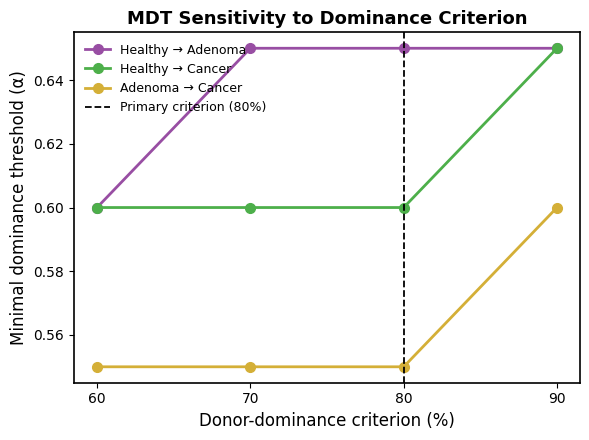

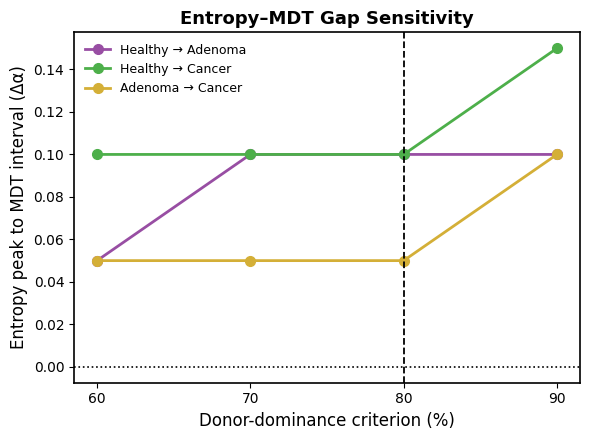


ROBUSTNESS SUMMARY
MDT THRESHOLD SENSITIVITY ANALYSIS

Thresholds tested: [0.6, 0.7, 0.8, 0.9]
Total comparisons: 12
Evaluable comparisons: 12
Entropy peak precedes MDT: 12/12
All peaks precede MDT: True
Adenoma-Cancer strictly lowest MDT at all thresholds: True

Interpretation:
This analysis evaluates robustness to the
operational donor-dominance criterion.
It does not independently establish
biological instability or resilience.

Analysis completed.
Results saved to: /content/MDT_Threshold_Sensitivity


In [ ]:

# ============================================================
# CRC MICROBIOME — MDT THRESHOLD SENSITIVITY ANALYSIS
# Test thresholds: 60%, 70%, 80%, 90%
#
# Inputs:
#   CRC_MDT_DoseResponse.csv
#   CRC_MDT_Entropy.csv
#
# Outputs:
#   1. MDT_Threshold_Sensitivity_ALL.csv
#   2. MDT_Threshold_Sensitivity_Wide.csv
#   3. MDT_Entropy_Gap_Sensitivity.png
#   4. MDT_Threshold_Comparison.png
#   5. MDT_Sensitivity_Summary.txt
# ============================================================

import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# ============================================================
# 0. SETTINGS
# ============================================================

DOSE_FILE = "/content/CRC_MDT_DoseResponse.csv"
ENTROPY_FILE = "/content/CRC_MDT_Entropy.csv"

OUTPUT_DIR = "/content/MDT_Threshold_Sensitivity"
os.makedirs(OUTPUT_DIR, exist_ok=True)

THRESHOLDS = [0.60, 0.70, 0.80, 0.90]
PRIMARY_THRESHOLD = 0.80

TRANSITIONS = [
    ("Healthy", "Adenoma"),
    ("Healthy", "Cancer"),
    ("Adenoma", "Cancer")
]

COLORS = {
    "Healthy → Adenoma": "#984ea3",
    "Healthy → Cancer": "#4daf4a",
    "Adenoma → Cancer": "#d4af37"
}

# ============================================================
# 1. LOAD ORIGINAL SIMULATION OUTPUTS
# ============================================================

dose = pd.read_csv(DOSE_FILE)
entropy = pd.read_csv(ENTROPY_FILE)

required_dose = [
    "Mode", "Recipient", "Donor",
    "alpha", "P_donor"
]

required_entropy = [
    "Recipient", "Donor",
    "alpha", "Entropy_mean"
]

assert all(c in dose.columns for c in required_dose)
assert all(c in entropy.columns for c in required_entropy)

# Use sample-level blending only
dose = dose[
    dose["Mode"] == "sample"
].copy()

dose["alpha"] = pd.to_numeric(dose["alpha"])
dose["P_donor"] = pd.to_numeric(dose["P_donor"])

entropy["alpha"] = pd.to_numeric(entropy["alpha"])
entropy["Entropy_mean"] = pd.to_numeric(
    entropy["Entropy_mean"]
)

print("Dose-response rows:", len(dose))
print("Entropy rows:", len(entropy))

# ============================================================
# 2. COMPUTE ENTROPY PEAKS
# ============================================================

entropy_peaks = {}

for recipient, donor in TRANSITIONS:

    sub = entropy[
        (entropy["Recipient"] == recipient) &
        (entropy["Donor"] == donor)
    ].sort_values("alpha")

    if sub.empty:
        raise ValueError(
            f"Missing entropy data: {recipient} -> {donor}"
        )

    peak_idx = sub["Entropy_mean"].idxmax()

    entropy_peaks[(recipient, donor)] = {
        "Alpha_at_entropy_peak":
            float(sub.loc[peak_idx, "alpha"]),

        "Peak_entropy":
            float(sub.loc[peak_idx, "Entropy_mean"])
    }

# ============================================================
# 3. MDT SENSITIVITY ANALYSIS
# ============================================================

results = []

for recipient, donor in TRANSITIONS:

    sub = dose[
        (dose["Recipient"] == recipient) &
        (dose["Donor"] == donor)
    ].sort_values("alpha")

    if sub.empty:
        raise ValueError(
            f"Missing dose-response: {recipient} -> {donor}"
        )

    peak = entropy_peaks[(recipient, donor)]

    alpha_peak = peak["Alpha_at_entropy_peak"]

    for threshold in THRESHOLDS:

        # Original MDT definition:
        # first alpha where >= threshold of simulated
        # profiles are classified as donor state

        crossing = sub[
            sub["P_donor"] >= threshold
        ]

        if crossing.empty:
            mdt = np.nan
            gap = np.nan
            precedes = False

        else:
            mdt = float(crossing["alpha"].iloc[0])

            gap = mdt - alpha_peak

            precedes = bool(gap > 0)

        results.append({
            "Recipient": recipient,
            "Donor": donor,
            "Transition": f"{recipient} → {donor}",
            "Dominance_threshold": threshold,
            "MDT_alpha": mdt,
            "Alpha_at_entropy_peak": alpha_peak,
            "Peak_entropy": peak["Peak_entropy"],
            "Entropy_MDT_gap": gap,
            "Entropy_precedes_MDT": precedes
        })

results_df = pd.DataFrame(results)

results_df.to_csv(
    f"{OUTPUT_DIR}/MDT_Threshold_Sensitivity_ALL.csv",
    index=False
)

print("\n======================================")
print("COMPLETE SENSITIVITY RESULTS")
print("======================================")

print(
    results_df.round(4).to_string(index=False)
)

# ============================================================
# 4. CREATE SUPPLEMENTARY WIDE TABLE
# ============================================================

wide = results_df.pivot(
    index="Transition",
    columns="Dominance_threshold",
    values=["MDT_alpha", "Entropy_MDT_gap"]
)

wide.columns = [
    f"{metric}_{int(threshold * 100)}pct"
    for metric, threshold in wide.columns
]

wide = wide.reindex(
    [f"{r} → {d}" for r, d in TRANSITIONS]
)

wide.to_csv(
    f"{OUTPUT_DIR}/MDT_Threshold_Sensitivity_Wide.csv"
)

print("\n======================================")
print("SUPPLEMENTARY TABLE")
print("======================================")

print(wide.round(3).to_string())

# ============================================================
# 5. FIGURE A — MDT ACROSS THRESHOLDS
# ============================================================

fig, ax = plt.subplots(figsize=(6, 4.5))

for transition in wide.index:

    sub = results_df[
        results_df["Transition"] == transition
    ].sort_values("Dominance_threshold")

    ax.plot(
        sub["Dominance_threshold"] * 100,
        sub["MDT_alpha"],
        marker="o",
        markersize=7,
        linewidth=2,
        color=COLORS[transition],
        label=transition
    )

ax.axvline(
    80,
    color="black",
    linestyle="--",
    linewidth=1.3,
    label="Primary criterion (80%)"
)

ax.set_xlabel(
    "Donor-dominance criterion (%)",
    fontsize=12
)

ax.set_ylabel(
    "Minimal dominance threshold (α)",
    fontsize=12
)

ax.set_title(
    "MDT Sensitivity to Dominance Criterion",
    fontsize=13,
    fontweight="bold"
)

ax.set_xticks([60, 70, 80, 90])

ax.legend(frameon=False, fontsize=9)

ax.grid(False)

for spine in ax.spines.values():
    spine.set_linewidth(1.2)

plt.tight_layout()

plt.savefig(
    f"{OUTPUT_DIR}/MDT_Threshold_Comparison.png",
    dpi=600,
    bbox_inches="tight"
)

plt.show()

# ============================================================
# 6. FIGURE B — ENTROPY–MDT GAP
# ============================================================

fig, ax = plt.subplots(figsize=(6, 4.5))

for transition in wide.index:

    sub = results_df[
        results_df["Transition"] == transition
    ].sort_values("Dominance_threshold")

    ax.plot(
        sub["Dominance_threshold"] * 100,
        sub["Entropy_MDT_gap"],
        marker="o",
        markersize=7,
        linewidth=2,
        color=COLORS[transition],
        label=transition
    )

ax.axhline(
    0,
    color="black",
    linestyle=":",
    linewidth=1.2
)

ax.axvline(
    80,
    color="black",
    linestyle="--",
    linewidth=1.3
)

ax.set_xlabel(
    "Donor-dominance criterion (%)",
    fontsize=12
)

ax.set_ylabel(
    "Entropy peak to MDT interval (Δα)",
    fontsize=12
)

ax.set_title(
    "Entropy–MDT Gap Sensitivity",
    fontsize=13,
    fontweight="bold"
)

ax.set_xticks([60, 70, 80, 90])

ax.legend(frameon=False, fontsize=9)

ax.grid(False)

for spine in ax.spines.values():
    spine.set_linewidth(1.2)

plt.tight_layout()

plt.savefig(
    f"{OUTPUT_DIR}/MDT_Entropy_Gap_Sensitivity.png",
    dpi=600,
    bbox_inches="tight"
)

plt.show()

# ============================================================
# 7. AUTOMATED ROBUSTNESS SUMMARY
# ============================================================

valid = results_df.dropna(
    subset=["MDT_alpha", "Entropy_MDT_gap"]
)

n_total = len(results_df)
n_valid = len(valid)

n_precedes = int(
    valid["Entropy_precedes_MDT"].sum()
)

all_precede = (
    n_valid == n_total and
    n_precedes == n_total
)

# Check whether Adenoma -> Cancer has lowest MDT
lowest_checks = []

for threshold in THRESHOLDS:

    sub = results_df[
        results_df["Dominance_threshold"] == threshold
    ]

    ac = sub[
        sub["Transition"] == "Adenoma → Cancer"
    ]["MDT_alpha"].iloc[0]

    other = sub[
        sub["Transition"] != "Adenoma → Cancer"
    ]["MDT_alpha"]

    lowest_checks.append(
        bool(
            np.isfinite(ac) and
            other.notna().all() and
            ac < other.min()
        )
    )

ac_always_lowest = all(lowest_checks)

summary = [
    "MDT THRESHOLD SENSITIVITY ANALYSIS",
    "====================================",
    "",
    f"Thresholds tested: {THRESHOLDS}",
    f"Total comparisons: {n_total}",
    f"Evaluable comparisons: {n_valid}",
    f"Entropy peak precedes MDT: {n_precedes}/{n_total}",
    f"All peaks precede MDT: {all_precede}",
    f"Adenoma-Cancer strictly lowest MDT "
    f"at all thresholds: {ac_always_lowest}",
    "",
    "Interpretation:",
    "This analysis evaluates robustness to the",
    "operational donor-dominance criterion.",
    "It does not independently establish",
    "biological instability or resilience."
]

summary_text = "\n".join(summary)

with open(
    f"{OUTPUT_DIR}/MDT_Sensitivity_Summary.txt",
    "w"
) as f:
    f.write(summary_text)

print("\n======================================")
print("ROBUSTNESS SUMMARY")
print("======================================")

print(summary_text)

print("\nAnalysis completed.")
print("Results saved to:", OUTPUT_DIR)


DATA VERIFICATION
Samples: 995
Species: 1023
Groups:
Cancer     479
Healthy    291
Adenoma    225
Name: count, dtype: int64

Observer trained.
Class order: ['Adenoma' 'Cancer' 'Healthy']

Healthy → Adenoma
MDT: 0.61
Entropy peak alpha: 0.54
Peak entropy: 1.294
Entropy-MDT gap: 0.07
Instability width: 0.56

Healthy → Cancer
MDT: 0.62
Entropy peak alpha: 0.54
Peak entropy: 1.319
Entropy-MDT gap: 0.08
Instability width: 0.44

Adenoma → Cancer
MDT: 0.57
Entropy peak alpha: 0.46
Peak entropy: 1.391
Entropy-MDT gap: 0.11
Instability width: 0.49

FINAL SUMMARY
       Transition Recipient   Donor  MDT_alpha  Alpha_at_entropy_peak  Peak_entropy  Entropy_MDT_gap  Instability_width  Entropy_precedes_MDT
Healthy → Adenoma   Healthy Adenoma       0.61                   0.54        1.2941             0.07               0.56                  True
 Healthy → Cancer   Healthy  Cancer       0.62                   0.54        1.3192             0.08               0.44                  True
 Adenoma → Can

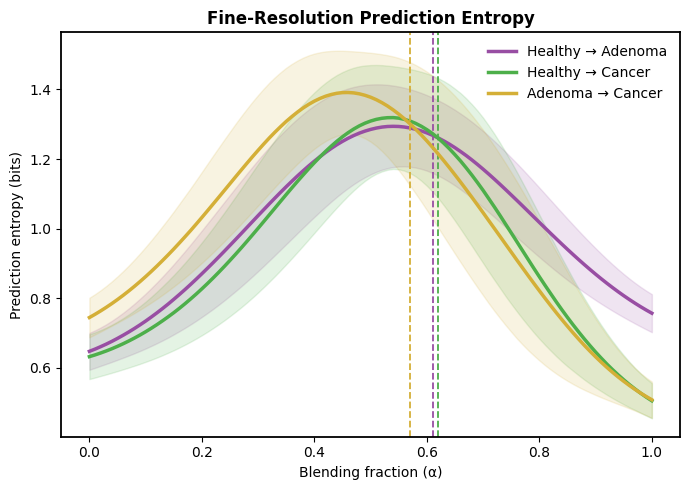

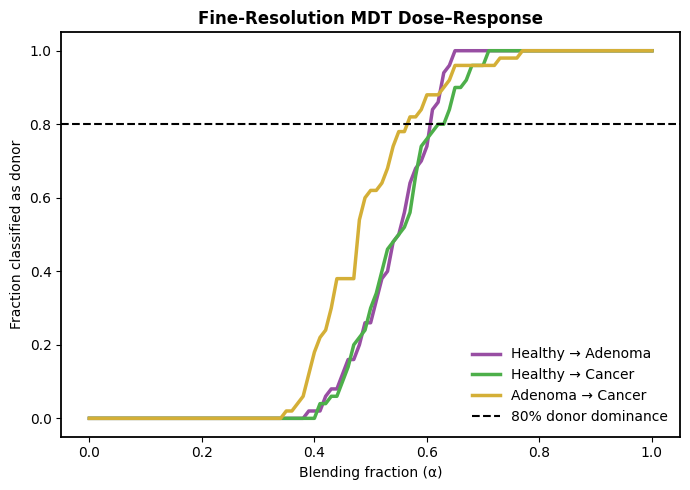

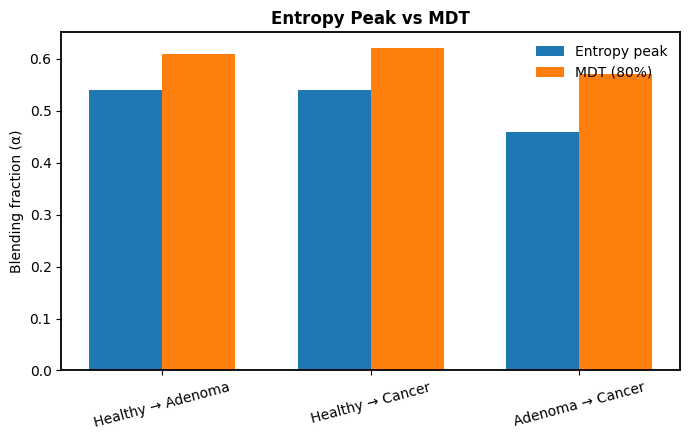


ROBUSTNESS INTERPRETATION
Entropy peak precedes MDT in all transitions: True
The ordering persists under finer alpha resolution and fixed-pair simulation.

Analysis completed.
Outputs saved to: /content/MDT_FineAlpha_Sensitivity


In [ ]:

# ============================================================
# CRC MICROBIOME
# FINE-RESOLUTION MDT AND ENTROPY SENSITIVITY ANALYSIS
# Alpha step: 0.01
# Dominance criterion: 80%
# Fixed recipient-donor pairs across alpha
# Original unscaled RBF-SVM
# ============================================================

import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from scipy.stats import entropy
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.svm import SVC

# ============================================================
# 0. SETTINGS
# ============================================================

RANDOM_STATE = 42
PAIR_SEED = 123

ALPHAS = np.linspace(0, 1, 101)
N_PAIRS = 50
DOMINANCE_THRESHOLD = 0.80

DATA_FILE = "/content/TPM_clr_batch_corrected_v2.csv"
META_FILE = "/content/CRC_metadata_aligned_bact.csv"

OUTPUT_DIR = "/content/MDT_FineAlpha_Sensitivity"
os.makedirs(OUTPUT_DIR, exist_ok=True)

TRANSITIONS = [
    ("Healthy", "Adenoma"),
    ("Healthy", "Cancer"),
    ("Adenoma", "Cancer")
]

COLORS = {
    "Healthy → Adenoma": "#984ea3",
    "Healthy → Cancer": "#4daf4a",
    "Adenoma → Cancer": "#d4af37"
}

ORIGINAL_MDT = {
    "Healthy → Adenoma": 0.65,
    "Healthy → Cancer": 0.60,
    "Adenoma → Cancer": 0.55
}

# ============================================================
# 1. LOAD AND ALIGN DATA
# ============================================================

X_df = pd.read_csv(DATA_FILE, index_col=0)
meta = pd.read_csv(META_FILE)

X_df.index = X_df.index.astype(str).str.strip()
meta["Sample_ID"] = meta["Sample_ID"].astype(str).str.strip()

if X_df.index.has_duplicates:
    raise ValueError("Duplicate sample IDs in matrix.")

if meta["Sample_ID"].duplicated().any():
    raise ValueError("Duplicate sample IDs in metadata.")

common = X_df.index.intersection(meta["Sample_ID"])

meta = (
    meta.set_index("Sample_ID")
        .loc[common]
        .copy()
)

X_df = X_df.loc[common]

meta = meta.dropna(subset=["Group"])
X_df = X_df.loc[meta.index]

X_df = X_df.apply(pd.to_numeric, errors="coerce")

if np.isinf(X_df.to_numpy()).any():
    raise ValueError("Infinite values detected.")

X = X_df.to_numpy()
y = meta["Group"].to_numpy()

print("======================================")
print("DATA VERIFICATION")
print("======================================")

print("Samples:", X.shape[0])
print("Species:", X.shape[1])
print("Groups:")
print(pd.Series(y).value_counts())

# ============================================================
# 2. TRAIN ORIGINAL SVM OBSERVER
# ============================================================

# No StandardScaler, matching original blending script.

model = Pipeline([
    (
        "imputer",
        SimpleImputer(strategy="median")
    ),
    (
        "svm",
        SVC(
            kernel="rbf",
            C=10,
            gamma="scale",
            probability=True,
            class_weight="balanced",
            random_state=RANDOM_STATE
        )
    )
])

# Full-dataset observer for descriptive simulations
model.fit(X, y)

classes = model.classes_

print("\nObserver trained.")
print("Class order:", classes)

# ============================================================
# 3. PREPARE GROUP MATRICES
# ============================================================

by_group = {
    group: X[y == group]
    for group in classes
}

rng = np.random.default_rng(PAIR_SEED)

dose_records = []
entropy_records = []
summary_records = []
pair_records = []

# ============================================================
# 4. FINE-RESOLUTION SIMULATION
# ============================================================

for recipient, donor in TRANSITIONS:

    transition = f"{recipient} → {donor}"

    Xr = by_group[recipient]
    Xd = by_group[donor]

    donor_idx = np.where(classes == donor)[0][0]

    # --------------------------------------------------------
    # Sample pairs ONCE for the entire alpha gradient
    # --------------------------------------------------------

    recipient_indices = rng.integers(
        0, len(Xr), size=N_PAIRS
    )

    donor_indices = rng.integers(
        0, len(Xd), size=N_PAIRS
    )

    recipient_samples = Xr[recipient_indices]
    donor_samples = Xd[donor_indices]

    for pair_id, (ri, di) in enumerate(
        zip(recipient_indices, donor_indices)
    ):
        pair_records.append({
            "Transition": transition,
            "Pair_ID": pair_id,
            "Recipient_index": int(ri),
            "Donor_index": int(di)
        })

    transition_dose = []
    transition_entropy = []

    # --------------------------------------------------------
    # Follow identical pairs across all alpha values
    # --------------------------------------------------------

    for alpha in ALPHAS:

        blends = (
            (1 - alpha) * recipient_samples
            + alpha * donor_samples
        )

        probabilities = model.predict_proba(blends)

        predicted_indices = np.argmax(
            probabilities,
            axis=1
        )

        donor_fraction = np.mean(
            predicted_indices == donor_idx
        )

        # Shannon entropy of class probabilities
        sample_entropies = entropy(
            probabilities,
            base=2,
            axis=1
        )

        mean_entropy = np.mean(sample_entropies)
        sd_entropy = np.std(sample_entropies)

        dose_records.append({
            "Transition": transition,
            "Recipient": recipient,
            "Donor": donor,
            "alpha": alpha,
            "P_donor": donor_fraction
        })

        entropy_records.append({
            "Transition": transition,
            "Recipient": recipient,
            "Donor": donor,
            "alpha": alpha,
            "Entropy_mean": mean_entropy,
            "Entropy_sd": sd_entropy
        })

        transition_dose.append(donor_fraction)
        transition_entropy.append(mean_entropy)

    # ========================================================
    # 5. COMPUTE MDT AND ENTROPY METRICS
    # ========================================================

    transition_dose = np.array(transition_dose)
    transition_entropy = np.array(transition_entropy)

    crossing = np.where(
        transition_dose >= DOMINANCE_THRESHOLD
    )[0]

    if len(crossing) > 0:
        mdt = ALPHAS[crossing[0]]
    else:
        mdt = np.nan

    peak_idx = np.argmax(transition_entropy)

    alpha_peak = ALPHAS[peak_idx]
    peak_entropy = transition_entropy[peak_idx]

    # Entropy-MDT gap
    gap = (
        mdt - alpha_peak
        if np.isfinite(mdt)
        else np.nan
    )

    # Original instability-width definition:
    # alpha range with entropy >=75% of peak entropy

    high_entropy = ALPHAS[
        transition_entropy >= 0.75 * peak_entropy
    ]

    instability_width = (
        high_entropy.max() - high_entropy.min()
        if len(high_entropy) > 1
        else 0.0
    )

    summary_records.append({
        "Transition": transition,
        "Recipient": recipient,
        "Donor": donor,
        "MDT_alpha": mdt,
        "Alpha_at_entropy_peak": alpha_peak,
        "Peak_entropy": peak_entropy,
        "Entropy_MDT_gap": gap,
        "Instability_width": instability_width,
        "Entropy_precedes_MDT": (
            bool(gap > 0)
            if np.isfinite(gap)
            else False
        )
    })

    print("\n======================================")
    print(transition)
    print("======================================")

    print("MDT:", round(mdt, 3))
    print("Entropy peak alpha:", round(alpha_peak, 3))
    print("Peak entropy:", round(peak_entropy, 3))
    print("Entropy-MDT gap:", round(gap, 3))
    print("Instability width:", round(instability_width, 3))

# ============================================================
# 6. SAVE RESULTS
# ============================================================

dose_df = pd.DataFrame(dose_records)
entropy_df = pd.DataFrame(entropy_records)
summary_df = pd.DataFrame(summary_records)
pairs_df = pd.DataFrame(pair_records)

dose_df.to_csv(
    f"{OUTPUT_DIR}/FineAlpha_DoseResponse.csv",
    index=False
)

entropy_df.to_csv(
    f"{OUTPUT_DIR}/FineAlpha_Entropy.csv",
    index=False
)

summary_df.to_csv(
    f"{OUTPUT_DIR}/FineAlpha_MDT_Summary.csv",
    index=False
)

pairs_df.to_csv(
    f"{OUTPUT_DIR}/FineAlpha_FixedPairs.csv",
    index=False
)

print("\n======================================")
print("FINAL SUMMARY")
print("======================================")

print(summary_df.round(4).to_string(index=False))

# ============================================================
# 7. COMPARE WITH ORIGINAL MDT
# ============================================================

comparison = summary_df[
    [
        "Transition",
        "MDT_alpha",
        "Alpha_at_entropy_peak",
        "Entropy_MDT_gap"
    ]
].copy()

comparison["Original_MDT"] = (
    comparison["Transition"].map(ORIGINAL_MDT)
)

comparison["MDT_Difference"] = (
    comparison["MDT_alpha"]
    - comparison["Original_MDT"]
)

comparison.to_csv(
    f"{OUTPUT_DIR}/FineAlpha_vs_Original_MDT.csv",
    index=False
)

print("\n======================================")
print("ORIGINAL VS FINE-ALPHA MDT")
print("======================================")

print(comparison.round(4).to_string(index=False))

# ============================================================
# 8. FIGURE A — ENTROPY CURVES
# ============================================================

fig, ax = plt.subplots(figsize=(7, 5))

for transition in COLORS:

    sub = entropy_df[
        entropy_df["Transition"] == transition
    ].sort_values("alpha")

    result = summary_df[
        summary_df["Transition"] == transition
    ].iloc[0]

    ax.plot(
        sub["alpha"],
        sub["Entropy_mean"],
        linewidth=2.5,
        color=COLORS[transition],
        label=transition
    )

    ax.fill_between(
        sub["alpha"].to_numpy(),
        (
            sub["Entropy_mean"]
            - sub["Entropy_sd"]
        ).to_numpy(),
        (
            sub["Entropy_mean"]
            + sub["Entropy_sd"]
        ).to_numpy(),
        color=COLORS[transition],
        alpha=0.15
    )

    ax.axvline(
        result["MDT_alpha"],
        color=COLORS[transition],
        linestyle="--",
        linewidth=1.3
    )

ax.set_xlabel("Blending fraction (α)")
ax.set_ylabel("Prediction entropy (bits)")
ax.set_title(
    "Fine-Resolution Prediction Entropy",
    fontweight="bold"
)

ax.legend(frameon=False)
ax.grid(False)

for spine in ax.spines.values():
    spine.set_linewidth(1.3)

plt.tight_layout()

plt.savefig(
    f"{OUTPUT_DIR}/FineAlpha_Entropy_Curves.png",
    dpi=600,
    bbox_inches="tight"
)

plt.show()

# ============================================================
# 9. FIGURE B — DONOR DOMINANCE
# ============================================================

fig, ax = plt.subplots(figsize=(7, 5))

for transition in COLORS:

    sub = dose_df[
        dose_df["Transition"] == transition
    ].sort_values("alpha")

    ax.plot(
        sub["alpha"],
        sub["P_donor"],
        linewidth=2.5,
        color=COLORS[transition],
        label=transition
    )

ax.axhline(
    DOMINANCE_THRESHOLD,
    color="black",
    linestyle="--",
    linewidth=1.5,
    label="80% donor dominance"
)

ax.set_xlabel("Blending fraction (α)")
ax.set_ylabel("Fraction classified as donor")
ax.set_title(
    "Fine-Resolution MDT Dose–Response",
    fontweight="bold"
)

ax.legend(frameon=False)
ax.grid(False)

for spine in ax.spines.values():
    spine.set_linewidth(1.3)

plt.tight_layout()

plt.savefig(
    f"{OUTPUT_DIR}/FineAlpha_DoseResponse.png",
    dpi=600,
    bbox_inches="tight"
)

plt.show()

# ============================================================
# 10. FIGURE C — MDT AND ENTROPY PEAK POSITION
# ============================================================

fig, ax = plt.subplots(figsize=(7, 4.5))

transitions = summary_df["Transition"].tolist()

x = np.arange(len(transitions))
width = 0.35

ax.bar(
    x - width / 2,
    summary_df["Alpha_at_entropy_peak"],
    width,
    label="Entropy peak"
)

ax.bar(
    x + width / 2,
    summary_df["MDT_alpha"],
    width,
    label="MDT (80%)"
)

ax.set_xticks(x)
ax.set_xticklabels(transitions, rotation=15)

ax.set_ylabel("Blending fraction (α)")
ax.set_title(
    "Entropy Peak vs MDT",
    fontweight="bold"
)

ax.legend(frameon=False)
ax.grid(False)

for spine in ax.spines.values():
    spine.set_linewidth(1.3)

plt.tight_layout()

plt.savefig(
    f"{OUTPUT_DIR}/FineAlpha_EntropyPeak_vs_MDT.png",
    dpi=600,
    bbox_inches="tight"
)

plt.show()

# ============================================================
# 11. ROBUSTNESS SUMMARY
# ============================================================

all_precede = summary_df[
    "Entropy_precedes_MDT"
].all()

print("\n======================================")
print("ROBUSTNESS INTERPRETATION")
print("======================================")

print(
    "Entropy peak precedes MDT in all transitions:",
    all_precede
)

if all_precede:
    print(
        "The ordering persists under finer alpha "
        "resolution and fixed-pair simulation."
    )
else:
    print(
        "At least one transition does not show "
        "entropy peaking before MDT."
    )

print("\nAnalysis completed.")
print("Outputs saved to:", OUTPUT_DIR)


DATA VERIFICATION
Samples: 995
Species: 1023
Groups:
Cancer     479
Healthy    291
Adenoma    225
Name: count, dtype: int64

Observer trained.
Class order: ['Adenoma' 'Cancer' 'Healthy']
Healthy → Adenoma | N=50 | MDT=0.610 | Peak=0.550 | Gap=0.060 | Width=0.570
Healthy → Adenoma | N=100 | MDT=0.610 | Peak=0.550 | Gap=0.060 | Width=0.560
Healthy → Adenoma | N=150 | MDT=0.610 | Peak=0.540 | Gap=0.070 | Width=0.550
Healthy → Cancer | N=50 | MDT=0.640 | Peak=0.540 | Gap=0.100 | Width=0.450
Healthy → Cancer | N=100 | MDT=0.620 | Peak=0.530 | Gap=0.090 | Width=0.450
Healthy → Cancer | N=150 | MDT=0.620 | Peak=0.520 | Gap=0.100 | Width=0.460
Adenoma → Cancer | N=50 | MDT=0.590 | Peak=0.470 | Gap=0.120 | Width=0.500
Adenoma → Cancer | N=100 | MDT=0.560 | Peak=0.470 | Gap=0.090 | Width=0.480
Adenoma → Cancer | N=150 | MDT=0.560 | Peak=0.470 | Gap=0.090 | Width=0.480

FINAL ROBUSTNESS SUMMARY
       Transition  N_pairs  MDT_alpha  Alpha_at_entropy_peak  Peak_entropy  Entropy_MDT_gap  Instabilit

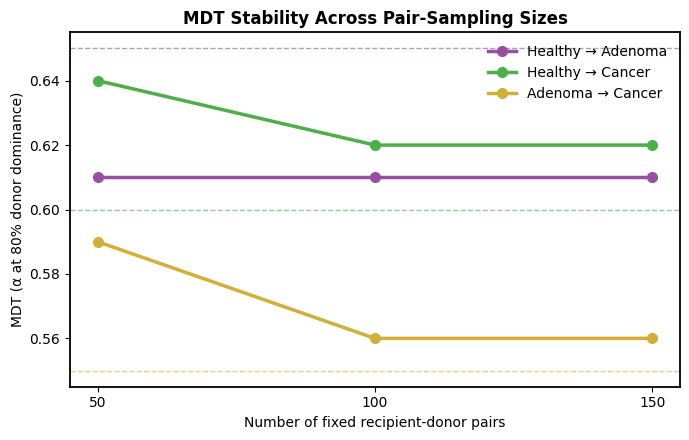

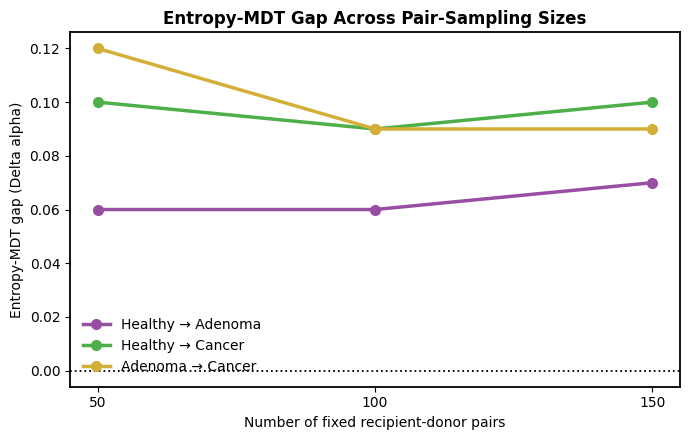


ENTROPY PRECEDES MDT?
N_pairs             50    100   150
Transition                         
Adenoma → Cancer   True  True  True
Healthy → Adenoma  True  True  True
Healthy → Cancer   True  True  True

Analysis completed.
Outputs saved to: /content/MDT_Final_Robustness


In [ ]:

# ============================================================
# CRC MICROBIOME — FINAL MDT ROBUSTNESS ANALYSIS
#Fixed recipient-donor pairs across alpha
# Alpha resolution: 0.01
# Dominance criterion: 80%
# ============================================================

import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from scipy.stats import entropy

from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.svm import SVC

# ============================================================
# 0. SETTINGS
# ============================================================

RANDOM_STATE = 42
PAIR_SEED = 123

ALPHAS = np.linspace(0, 1, 101)

PAIR_SIZES = [50, 100, 150]

DOMINANCE_THRESHOLD = 0.80

DATA_FILE = "/content/TPM_clr_batch_corrected_v2.csv"
META_FILE = "/content/CRC_metadata_aligned_bact.csv"

OUTPUT_DIR = "/content/MDT_Final_Robustness"
os.makedirs(OUTPUT_DIR, exist_ok=True)

TRANSITIONS = [
    ("Healthy", "Adenoma"),
    ("Healthy", "Cancer"),
    ("Adenoma", "Cancer")
]

COLORS = {
    "Healthy → Adenoma": "#984ea3",
    "Healthy → Cancer": "#4daf4a",
    "Adenoma → Cancer": "#d4af37"
}

ORIGINAL_MDT = {
    "Healthy → Adenoma": 0.65,
    "Healthy → Cancer": 0.60,
    "Adenoma → Cancer": 0.55
}

# ============================================================
# 1. LOAD AND ALIGN DATA
# ============================================================

X_df = pd.read_csv(DATA_FILE, index_col=0)
meta = pd.read_csv(META_FILE)

X_df.index = X_df.index.astype(str).str.strip()
meta["Sample_ID"] = (
    meta["Sample_ID"].astype(str).str.strip()
)

if X_df.index.has_duplicates:
    raise ValueError("Duplicate sample IDs in matrix.")

if meta["Sample_ID"].duplicated().any():
    raise ValueError("Duplicate sample IDs in metadata.")

common = X_df.index.intersection(meta["Sample_ID"])

meta = (
    meta.set_index("Sample_ID")
        .loc[common]
        .copy()
)

X_df = X_df.loc[common]

meta = meta.dropna(subset=["Group"])
X_df = X_df.loc[meta.index]

X_df = X_df.apply(pd.to_numeric, errors="coerce")

if np.isinf(X_df.to_numpy()).any():
    raise ValueError("Infinite values detected.")

X = X_df.to_numpy()
y = meta["Group"].to_numpy()

print("======================================")
print("DATA VERIFICATION")
print("======================================")

print("Samples:", X.shape[0])
print("Species:", X.shape[1])
print("Groups:")
print(pd.Series(y).value_counts())

# ============================================================
# 2. TRAIN ORIGINAL SVM OBSERVER
# ============================================================

# No StandardScaler, matching original blending script

model = Pipeline([
    (
        "imputer",
        SimpleImputer(strategy="median")
    ),
    (
        "svm",
        SVC(
            kernel="rbf",
            C=10,
            gamma="scale",
            probability=True,
            class_weight="balanced",
            random_state=RANDOM_STATE
        )
    )
])

model.fit(X, y)

classes = model.classes_

print("\nObserver trained.")
print("Class order:", classes)

# ============================================================
# 3. PREPARE GROUP MATRICES
# ============================================================

by_group = {
    group: X[y == group]
    for group in classes
}

# ============================================================
# 4. SIMULATE FIXED PAIRS
# ============================================================

dose_records = []
entropy_records = []
summary_records = []

# Independent random stream for each transition
# Reuse the same first 50, 200, 500 pairs
# so comparisons are nested and reproducible.

for recipient, donor in TRANSITIONS:

    transition = f"{recipient} → {donor}"

    Xr = by_group[recipient]
    Xd = by_group[donor]

    donor_idx = np.where(classes == donor)[0][0]

    rng = np.random.default_rng(
        PAIR_SEED + TRANSITIONS.index((recipient, donor))
    )

    # Generate maximum number of pairs once
    max_pairs = max(PAIR_SIZES)

    recipient_indices = rng.integers(
        0, len(Xr), size=max_pairs
    )

    donor_indices = rng.integers(
        0, len(Xd), size=max_pairs
    )

    all_recipient = Xr[recipient_indices]
    all_donor = Xd[donor_indices]

    for n_pairs in PAIR_SIZES:

        recipient_samples = all_recipient[:n_pairs]
        donor_samples = all_donor[:n_pairs]

        transition_dose = []
        transition_entropy = []

        for alpha in ALPHAS:

            blends = (
                (1 - alpha) * recipient_samples
                + alpha * donor_samples
            )

            probabilities = model.predict_proba(blends)

            predicted_indices = np.argmax(
                probabilities,
                axis=1
            )

            donor_fraction = np.mean(
                predicted_indices == donor_idx
            )

            sample_entropies = entropy(
                probabilities,
                base=2,
                axis=1
            )

            mean_entropy = np.mean(sample_entropies)
            sd_entropy = np.std(sample_entropies)

            dose_records.append({
                "Transition": transition,
                "N_pairs": n_pairs,
                "alpha": alpha,
                "P_donor": donor_fraction
            })

            entropy_records.append({
                "Transition": transition,
                "N_pairs": n_pairs,
                "alpha": alpha,
                "Entropy_mean": mean_entropy,
                "Entropy_sd": sd_entropy
            })

            transition_dose.append(donor_fraction)
            transition_entropy.append(mean_entropy)

        # ====================================================
        # 5. COMPUTE MDT AND ENTROPY METRICS
        # ====================================================

        transition_dose = np.array(transition_dose)
        transition_entropy = np.array(transition_entropy)

        crossing = np.where(
            transition_dose >= DOMINANCE_THRESHOLD
        )[0]

        mdt = (
            ALPHAS[crossing[0]]
            if len(crossing) > 0
            else np.nan
        )

        peak_idx = np.argmax(transition_entropy)

        alpha_peak = ALPHAS[peak_idx]
        peak_entropy = transition_entropy[peak_idx]

        gap = (
            mdt - alpha_peak
            if np.isfinite(mdt)
            else np.nan
        )

        high_entropy = ALPHAS[
            transition_entropy >= 0.75 * peak_entropy
        ]

        instability_width = (
            high_entropy.max() - high_entropy.min()
            if len(high_entropy) > 1
            else 0.0
        )

        summary_records.append({
            "Transition": transition,
            "N_pairs": n_pairs,
            "MDT_alpha": mdt,
            "Alpha_at_entropy_peak": alpha_peak,
            "Peak_entropy": peak_entropy,
            "Entropy_MDT_gap": gap,
            "Instability_width": instability_width,
            "Entropy_precedes_MDT": (
                bool(gap > 0)
                if np.isfinite(gap)
                else False
            )
        })

        print(
            f"{transition} | "
            f"N={n_pairs} | "
            f"MDT={mdt:.3f} | "
            f"Peak={alpha_peak:.3f} | "
            f"Gap={gap:.3f} | "
            f"Width={instability_width:.3f}"
        )

# ============================================================
# 6. SAVE RESULTS
# ============================================================

dose_df = pd.DataFrame(dose_records)
entropy_df = pd.DataFrame(entropy_records)
summary_df = pd.DataFrame(summary_records)

dose_df.to_csv(
    f"{OUTPUT_DIR}/MDT_Robustness_DoseResponse.csv",
    index=False
)

entropy_df.to_csv(
    f"{OUTPUT_DIR}/MDT_Robustness_Entropy.csv",
    index=False
)

summary_df.to_csv(
    f"{OUTPUT_DIR}/MDT_Robustness_Summary.csv",
    index=False
)

print("\n======================================")
print("FINAL ROBUSTNESS SUMMARY")
print("======================================")

print(
    summary_df.round(4).to_string(index=False)
)

# ============================================================
# 7. COMPARISON WITH ORIGINAL MDT
# ============================================================

comparison = summary_df.copy()

comparison["Original_MDT"] = (
    comparison["Transition"].map(ORIGINAL_MDT)
)

comparison["MDT_Difference"] = (
    comparison["MDT_alpha"]
    - comparison["Original_MDT"]
)

comparison.to_csv(
    f"{OUTPUT_DIR}/MDT_Robustness_vs_Original.csv",
    index=False
)

# ============================================================
# 8. FIGURE — MDT BY NUMBER OF PAIRS
# ============================================================

fig, ax = plt.subplots(figsize=(7, 4.5))

for transition in COLORS:

    sub = summary_df[
        summary_df["Transition"] == transition
    ].sort_values("N_pairs")

    ax.plot(
        sub["N_pairs"],
        sub["MDT_alpha"],
        marker="o",
        markersize=7,
        linewidth=2.5,
        color=COLORS[transition],
        label=transition
    )

    ax.axhline(
        ORIGINAL_MDT[transition],
        color=COLORS[transition],
        linestyle="--",
        linewidth=1,
        alpha=0.6
    )

ax.set_xlabel("Number of fixed recipient-donor pairs")
ax.set_ylabel("MDT (α at 80% donor dominance)")
ax.set_title(
    "MDT Stability Across Pair-Sampling Sizes",
    fontweight="bold"
)

ax.set_xticks(PAIR_SIZES)
ax.legend(frameon=False)

ax.grid(False)

for spine in ax.spines.values():
    spine.set_linewidth(1.3)

plt.tight_layout()

plt.savefig(
    f"{OUTPUT_DIR}/MDT_vs_NumberOfPairs.png",
    dpi=600,
    bbox_inches="tight"
)

plt.show()

# ============================================================
# 9. FIGURE — ENTROPY-MDT GAP
# ============================================================

fig, ax = plt.subplots(figsize=(7, 4.5))

for transition in COLORS:

    sub = summary_df[
        summary_df["Transition"] == transition
    ].sort_values("N_pairs")

    ax.plot(
        sub["N_pairs"],
        sub["Entropy_MDT_gap"],
        marker="o",
        markersize=7,
        linewidth=2.5,
        color=COLORS[transition],
        label=transition
    )

ax.axhline(
    0,
    color="black",
    linestyle=":",
    linewidth=1.3
)

ax.set_xlabel("Number of fixed recipient-donor pairs")
ax.set_ylabel("Entropy-MDT gap (Delta alpha)")
ax.set_title(
    "Entropy-MDT Gap Across Pair-Sampling Sizes",
    fontweight="bold"
)

ax.set_xticks(PAIR_SIZES)
ax.legend(frameon=False)

ax.grid(False)

for spine in ax.spines.values():
    spine.set_linewidth(1.3)

plt.tight_layout()

plt.savefig(
    f"{OUTPUT_DIR}/Entropy_MDT_Gap_vs_Pairs.png",
    dpi=600,
    bbox_inches="tight"
)

plt.show()

# ============================================================
# 10. FINAL CHECK
# ============================================================

print("\n======================================")
print("ENTROPY PRECEDES MDT?")
print("======================================")

print(
    summary_df.pivot(
        index="Transition",
        columns="N_pairs",
        values="Entropy_precedes_MDT"
    )
)

print("\nAnalysis completed.")
print("Outputs saved to:", OUTPUT_DIR)


DATA VERIFICATION
Samples: 995
Species: 1023
Groups:
Cancer     479
Healthy    291
Adenoma    225
Name: count, dtype: int64

Observer trained.
Class order: ['Adenoma' 'Cancer' 'Healthy']
[1/180] Healthy → Adenoma | resample_each_alpha | N=50 | Seed=42 | MDT=0.65 | Gap=0.10
[2/180] Healthy → Adenoma | resample_each_alpha | N=50 | Seed=123 | MDT=0.60 | Gap=0.10
[3/180] Healthy → Adenoma | resample_each_alpha | N=50 | Seed=456 | MDT=0.65 | Gap=0.10
[4/180] Healthy → Adenoma | resample_each_alpha | N=50 | Seed=789 | MDT=0.65 | Gap=0.10
[5/180] Healthy → Adenoma | resample_each_alpha | N=50 | Seed=2026 | MDT=0.65 | Gap=0.05
[6/180] Healthy → Adenoma | resample_each_alpha | N=50 | Seed=11 | MDT=0.60 | Gap=0.10
[7/180] Healthy → Adenoma | resample_each_alpha | N=50 | Seed=22 | MDT=0.65 | Gap=0.10
[8/180] Healthy → Adenoma | resample_each_alpha | N=50 | Seed=33 | MDT=0.65 | Gap=0.10
[9/180] Healthy → Adenoma | resample_each_alpha | N=50 | Seed=44 | MDT=0.60 | Gap=0.10
[10/180] Healthy → Adenom

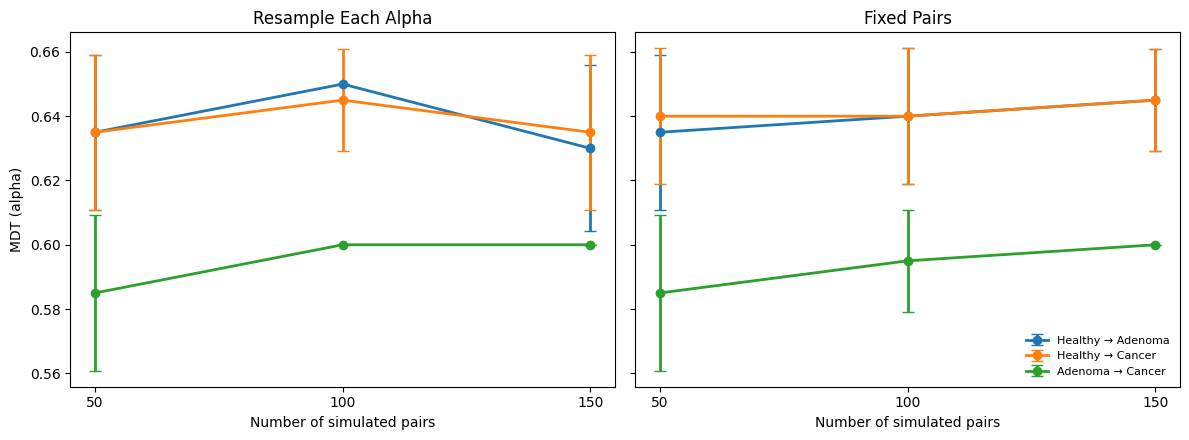

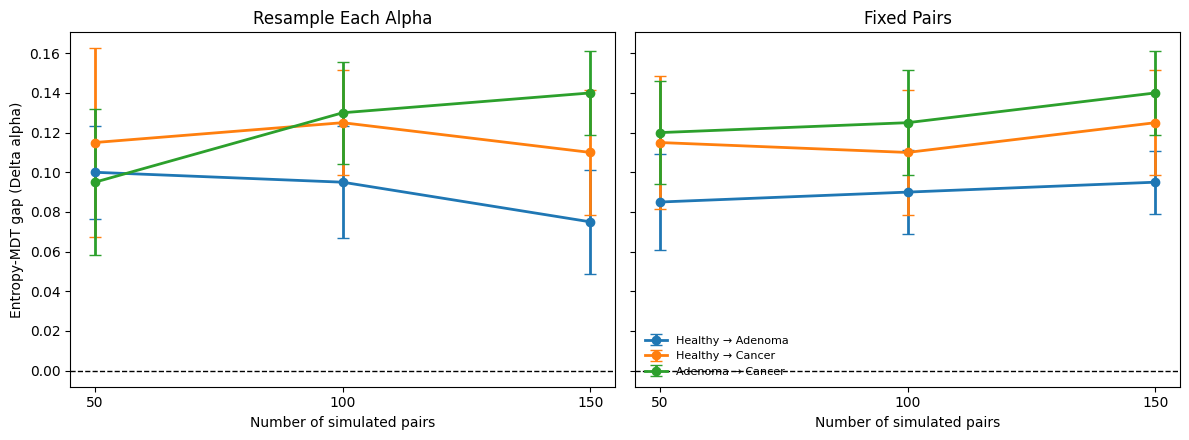


TRANSITION ORDERING ROBUSTNESS
           Strategy  N_pairs  Fraction_AC_lowest  Fraction_full_ordering
        fixed_pairs       50                 0.6                     0.1
        fixed_pairs      100                 0.6                     0.0
        fixed_pairs      150                 0.8                     0.0
resample_each_alpha       50                 0.7                     0.0
resample_each_alpha      100                 0.9                     0.0
resample_each_alpha      150                 0.5                     0.0

ENTROPY PRECEDES MDT — FRACTION OF RUNS
       Transition            Strategy  N_pairs  Fraction_entropy_precedes
 Adenoma → Cancer         fixed_pairs       50                        1.0
 Adenoma → Cancer         fixed_pairs      100                        1.0
 Adenoma → Cancer         fixed_pairs      150                        1.0
 Adenoma → Cancer resample_each_alpha       50                        1.0
 Adenoma → Cancer resample_each_alpha      100

In [ ]:

# ============================================================
# CRC MICROBIOME — MDT SAMPLING ROBUSTNESS
#
# Alpha increment: 0.05
# Donor dominance criterion: 80%
# Pair counts: 50, 100, 150
# Independent seeds: 10
# Sampling strategies:
#   1. Resample pairs independently at every alpha
#   2. Fixed pairs across all alpha values
#
# Original unscaled RBF-SVM observer
# ============================================================

import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.svm import SVC

# ============================================================
# 0. SETTINGS
# ============================================================

DATA_FILE = "/content/TPM_clr_batch_corrected_v2.csv"
META_FILE = "/content/CRC_metadata_aligned_bact.csv"

OUTPUT_DIR = "/content/MDT_Independent_Seed_Robustness"
os.makedirs(OUTPUT_DIR, exist_ok=True)

MODEL_SEED = 42

SEEDS = [42, 123, 456, 789, 2026,
         11, 22, 33, 44, 55]

PAIR_SIZES = [50, 100, 150]

ALPHAS = np.linspace(0, 1, 21)

DOMINANCE_THRESHOLD = 0.80

STRATEGIES = [
    "resample_each_alpha",
    "fixed_pairs"
]

TRANSITIONS = [
    ("Healthy", "Adenoma"),
    ("Healthy", "Cancer"),
    ("Adenoma", "Cancer")
]

ORIGINAL_MDT = {
    "Healthy → Adenoma": 0.65,
    "Healthy → Cancer": 0.60,
    "Adenoma → Cancer": 0.55
}

# ============================================================
# 1. LOAD AND ALIGN DATA
# ============================================================

X_df = pd.read_csv(DATA_FILE, index_col=0)
meta = pd.read_csv(META_FILE)

X_df.index = X_df.index.astype(str).str.strip()
meta["Sample_ID"] = (
    meta["Sample_ID"].astype(str).str.strip()
)

if X_df.index.has_duplicates:
    raise ValueError("Duplicate sample IDs in matrix.")

if meta["Sample_ID"].duplicated().any():
    raise ValueError("Duplicate sample IDs in metadata.")

common = X_df.index.intersection(meta["Sample_ID"])

meta = (
    meta.set_index("Sample_ID")
        .loc[common]
        .copy()
)

X_df = X_df.loc[common]

meta = meta.dropna(subset=["Group"])
X_df = X_df.loc[meta.index]

X_df = X_df.apply(pd.to_numeric, errors="coerce")

if np.isinf(X_df.to_numpy()).any():
    raise ValueError("Infinite values detected.")

X = X_df.to_numpy()
y = meta["Group"].to_numpy()

print("=" * 60)
print("DATA VERIFICATION")
print("=" * 60)

print("Samples:", X.shape[0])
print("Species:", X.shape[1])
print("Groups:")
print(pd.Series(y).value_counts())

# ============================================================
# 2. TRAIN ORIGINAL SVM OBSERVER
# ============================================================

# No StandardScaler, matching the original MDT simulation.

model = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("svm", SVC(
        kernel="rbf",
        C=10,
        gamma="scale",
        probability=True,
        class_weight="balanced",
        random_state=MODEL_SEED
    ))
])

model.fit(X, y)
classes = model.classes_

print("\nObserver trained.")
print("Class order:", classes)

by_group = {
    group: X[y == group]
    for group in classes
}

# ============================================================
# 3. SIMULATION FUNCTION
# ============================================================

def run_simulation(
    recipient,
    donor,
    n_pairs,
    seed,
    strategy
):

    Xr = by_group[recipient]
    Xd = by_group[donor]

    donor_idx = np.where(classes == donor)[0][0]

    rng = np.random.default_rng(seed)

    # Fixed pairs are sampled once.
    if strategy == "fixed_pairs":

        r_idx = rng.integers(
            len(Xr), size=n_pairs
        )

        d_idx = rng.integers(
            len(Xd), size=n_pairs
        )

        fixed_r = Xr[r_idx]
        fixed_d = Xd[d_idx]

    dose_values = []
    entropy_values = []

    for alpha in ALPHAS:

        if strategy == "resample_each_alpha":

            r_idx = rng.integers(
                len(Xr), size=n_pairs
            )

            d_idx = rng.integers(
                len(Xd), size=n_pairs
            )

            xr = Xr[r_idx]
            xd = Xd[d_idx]

        else:

            xr = fixed_r
            xd = fixed_d

        blends = (1 - alpha) * xr + alpha * xd

        probabilities = model.predict_proba(blends)

        predicted_idx = np.argmax(
            probabilities, axis=1
        )

        donor_fraction = np.mean(
            predicted_idx == donor_idx
        )

        # Shannon entropy in bits
        p_safe = np.clip(
            probabilities, 1e-15, 1
        )

        entropies = -np.sum(
            p_safe * np.log2(p_safe),
            axis=1
        )

        dose_values.append(donor_fraction)
        entropy_values.append(np.mean(entropies))

    dose_values = np.array(dose_values)
    entropy_values = np.array(entropy_values)

    # --------------------------------------------------------
    # MDT
    # --------------------------------------------------------

    crossing = np.where(
        dose_values >= DOMINANCE_THRESHOLD
    )[0]

    mdt = (
        float(ALPHAS[crossing[0]])
        if len(crossing) > 0
        else np.nan
    )

    # --------------------------------------------------------
    # Entropy peak and gap
    # --------------------------------------------------------

    peak_idx = np.argmax(entropy_values)

    alpha_peak = float(ALPHAS[peak_idx])
    peak_entropy = float(entropy_values[peak_idx])

    gap = (
        mdt - alpha_peak
        if np.isfinite(mdt)
        else np.nan
    )

    # Original instability-width definition
    high_entropy_alpha = ALPHAS[
        entropy_values >= 0.75 * peak_entropy
    ]

    width = (
        float(
            high_entropy_alpha.max()
            - high_entropy_alpha.min()
        )
        if len(high_entropy_alpha) > 1
        else 0.0
    )

    return {
        "MDT_alpha": mdt,
        "Alpha_at_entropy_peak": alpha_peak,
        "Peak_entropy": peak_entropy,
        "Entropy_MDT_gap": gap,
        "Instability_width": width,
        "Entropy_precedes_MDT": (
            bool(gap > 0)
            if np.isfinite(gap)
            else False
        )
    }

# ============================================================
# 4. RUN ALL CONFIGURATIONS
# ============================================================

records = []

total_runs = (
    len(TRANSITIONS)
    * len(SEEDS)
    * len(PAIR_SIZES)
    * len(STRATEGIES)
)

run_number = 0

for recipient, donor in TRANSITIONS:

    transition = f"{recipient} → {donor}"

    for strategy in STRATEGIES:

        for n_pairs in PAIR_SIZES:

            for seed in SEEDS:

                run_number += 1

                result = run_simulation(
                    recipient=recipient,
                    donor=donor,
                    n_pairs=n_pairs,
                    seed=seed,
                    strategy=strategy
                )

                records.append({
                    "Transition": transition,
                    "Strategy": strategy,
                    "N_pairs": n_pairs,
                    "Seed": seed,
                    **result
                })

                print(
                    f"[{run_number}/{total_runs}] "
                    f"{transition} | "
                    f"{strategy} | "
                    f"N={n_pairs} | "
                    f"Seed={seed} | "
                    f"MDT={result['MDT_alpha']:.2f} | "
                    f"Gap={result['Entropy_MDT_gap']:.2f}"
                )

results_df = pd.DataFrame(records)

results_df.to_csv(
    f"{OUTPUT_DIR}/MDT_All_Independent_Seed_Results.csv",
    index=False
)

# ============================================================
# 5. SUMMARIZE ACROSS INDEPENDENT SEEDS
# ============================================================

summary_df = (
    results_df
    .groupby(
        ["Transition", "Strategy", "N_pairs"]
    )
    .agg(
        MDT_median=("MDT_alpha", "median"),
        MDT_mean=("MDT_alpha", "mean"),
        MDT_sd=("MDT_alpha", "std"),
        MDT_min=("MDT_alpha", "min"),
        MDT_max=("MDT_alpha", "max"),

        Peak_alpha_median=(
            "Alpha_at_entropy_peak", "median"
        ),

        Gap_median=("Entropy_MDT_gap", "median"),
        Gap_mean=("Entropy_MDT_gap", "mean"),
        Gap_sd=("Entropy_MDT_gap", "std"),
        Gap_min=("Entropy_MDT_gap", "min"),
        Gap_max=("Entropy_MDT_gap", "max"),

        Width_median=("Instability_width", "median"),

        Fraction_entropy_precedes=(
            "Entropy_precedes_MDT", "mean"
        )
    )
    .reset_index()
)

summary_df.to_csv(
    f"{OUTPUT_DIR}/MDT_Seed_Robustness_Summary.csv",
    index=False
)

print("\n" + "=" * 60)
print("ROBUSTNESS SUMMARY ACROSS SEEDS")
print("=" * 60)

print(summary_df.round(4).to_string(index=False))

# ============================================================
# 6. FIGURE — MDT ACROSS SEEDS
# ============================================================

fig, axes = plt.subplots(
    1, 2,
    figsize=(12, 4.5),
    sharey=True
)

for ax, strategy in zip(axes, STRATEGIES):

    sub = results_df[
        results_df["Strategy"] == strategy
    ]

    for transition in sub["Transition"].unique():

        group = sub[
            sub["Transition"] == transition
        ]

        means = (
            group.groupby("N_pairs")["MDT_alpha"]
            .mean()
            .reindex(PAIR_SIZES)
        )

        sds = (
            group.groupby("N_pairs")["MDT_alpha"]
            .std()
            .reindex(PAIR_SIZES)
        )

        ax.errorbar(
            PAIR_SIZES,
            means,
            yerr=sds,
            marker="o",
            linewidth=2,
            capsize=4,
            label=transition
        )

    ax.set_title(
        strategy.replace("_", " ").title()
    )

    ax.set_xlabel("Number of simulated pairs")
    ax.set_xticks(PAIR_SIZES)
    ax.grid(False)

axes[0].set_ylabel("MDT (alpha)")
axes[1].legend(frameon=False, fontsize=8)

plt.tight_layout()

plt.savefig(
    f"{OUTPUT_DIR}/MDT_Seed_Robustness.png",
    dpi=600,
    bbox_inches="tight"
)

plt.show()

# ============================================================
# 7. FIGURE — ENTROPY-MDT GAP ACROSS SEEDS
# ============================================================

fig, axes = plt.subplots(
    1, 2,
    figsize=(12, 4.5),
    sharey=True
)

for ax, strategy in zip(axes, STRATEGIES):

    sub = results_df[
        results_df["Strategy"] == strategy
    ]

    for transition in sub["Transition"].unique():

        group = sub[
            sub["Transition"] == transition
        ]

        means = (
            group.groupby("N_pairs")["Entropy_MDT_gap"]
            .mean()
            .reindex(PAIR_SIZES)
        )

        sds = (
            group.groupby("N_pairs")["Entropy_MDT_gap"]
            .std()
            .reindex(PAIR_SIZES)
        )

        ax.errorbar(
            PAIR_SIZES,
            means,
            yerr=sds,
            marker="o",
            linewidth=2,
            capsize=4,
            label=transition
        )

    ax.axhline(
        0,
        color="black",
        linestyle="--",
        linewidth=1
    )

    ax.set_title(
        strategy.replace("_", " ").title()
    )

    ax.set_xlabel("Number of simulated pairs")
    ax.set_xticks(PAIR_SIZES)
    ax.grid(False)

axes[0].set_ylabel("Entropy-MDT gap (Delta alpha)")
axes[1].legend(frameon=False, fontsize=8)

plt.tight_layout()

plt.savefig(
    f"{OUTPUT_DIR}/Entropy_MDT_Gap_Seed_Robustness.png",
    dpi=600,
    bbox_inches="tight"
)

plt.show()

# ============================================================
# 8. CHECK TRANSITION ORDERING WITHIN EACH SEED
# ============================================================

ordering_records = []

for (strategy, n_pairs, seed), sub in results_df.groupby(
    ["Strategy", "N_pairs", "Seed"]
):

    values = sub.set_index("Transition")["MDT_alpha"]

    ac = values["Adenoma → Cancer"]
    ha = values["Healthy → Adenoma"]
    hc = values["Healthy → Cancer"]

    ordering_records.append({
        "Strategy": strategy,
        "N_pairs": n_pairs,
        "Seed": seed,
        "Adenoma_Cancer_lowest": bool(
            np.isfinite([ac, ha, hc]).all()
            and ac < min(ha, hc)
        ),
        "Full_original_ordering": bool(
            np.isfinite([ac, ha, hc]).all()
            and ac < hc < ha
        )
    })

ordering_df = pd.DataFrame(ordering_records)

ordering_df.to_csv(
    f"{OUTPUT_DIR}/MDT_Ordering_BySeed.csv",
    index=False
)

ordering_summary = (
    ordering_df
    .groupby(["Strategy", "N_pairs"])
    .agg(
        Fraction_AC_lowest=(
            "Adenoma_Cancer_lowest", "mean"
        ),
        Fraction_full_ordering=(
            "Full_original_ordering", "mean"
        )
    )
    .reset_index()
)

ordering_summary.to_csv(
    f"{OUTPUT_DIR}/MDT_Ordering_Summary.csv",
    index=False
)

print("\n" + "=" * 60)
print("TRANSITION ORDERING ROBUSTNESS")
print("=" * 60)

print(
    ordering_summary.round(3).to_string(index=False)
)

# ============================================================
# 9. FINAL CHECK
# ============================================================

print("\n" + "=" * 60)
print("ENTROPY PRECEDES MDT — FRACTION OF RUNS")
print("=" * 60)

print(
    summary_df[
        [
            "Transition",
            "Strategy",
            "N_pairs",
            "Fraction_entropy_precedes"
        ]
    ].to_string(index=False)
)

print("\nAnalysis completed.")
print("Outputs saved to:", OUTPUT_DIR)
